##### Recherche du minimum

##### Graphiques

In [2]:
from algo.neldermead import NelderMead, init_simplex
from utils.point import Point

def f(p: Point)->float:
    result = 0

    for x in p:
        result += x**4

    return result

n_itr = 300000
epsilon = 10**-8

best_values = []
history_step = []

times = []

for i in range(10):
    simplex = init_simplex([1 for i in range(10)], 0.5)
    algo = NelderMead(
        simplex,
        f,
        scalaire_reflexion=1.5,
        scalaire_expansion=2,
        scalaire_contraction=0.5,
        scalaire_homothetie=0.5
    )
    algo.compute(n_itr)

    best_point = algo.history_benchmark["best_points"][-1]
    best_value = algo.history_benchmark["best_values"][-1]

    best_values = [v for v in algo.history_benchmark["best_values"] if v > epsilon]

    history_step = [v for v in algo.history if v["step"] < len(best_values) ]

    if i == 0:
        print("Meilleur point:", best_point)
        print("Valeur du meilleur point:", best_value)
        print("Itération avant convergence:", len(best_values))

    __times = algo.history_benchmark["execution_time"]
    _times = [__times[i] for i in range(len(best_values))]
    times.append(sum(_times) / len(_times))

print("Temps d'exécution:", sum(times), "ns")
print("Temps d'exécution moyens par itr: ", sum(times) / len(times), "ns")

Meilleur point: Point([0.0007633180253205486, 0.0003949582310555773, 0.0010251062813373228, -0.001157510670455431, -0.00044443162179611407, -0.0008887507505580413, -0.0008872033916837148, -0.00134465659473379, 0.0011533488749105609, 0.0013376771319826275], Dimension: 10)
Valeur du meilleur point: 1.2786311855149898e-11
Itération avant convergence: 250994
Temps d'exécution: 60170.307457548784 ns


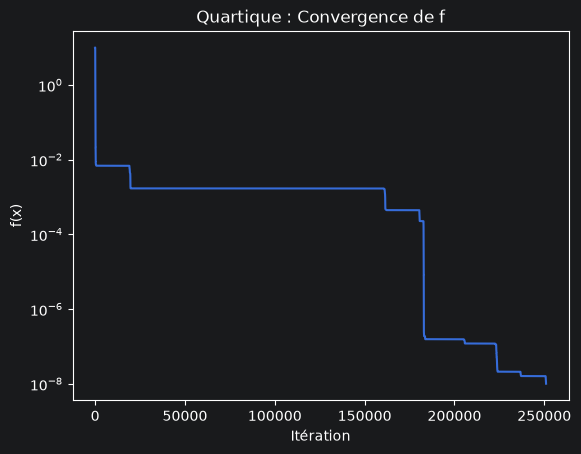

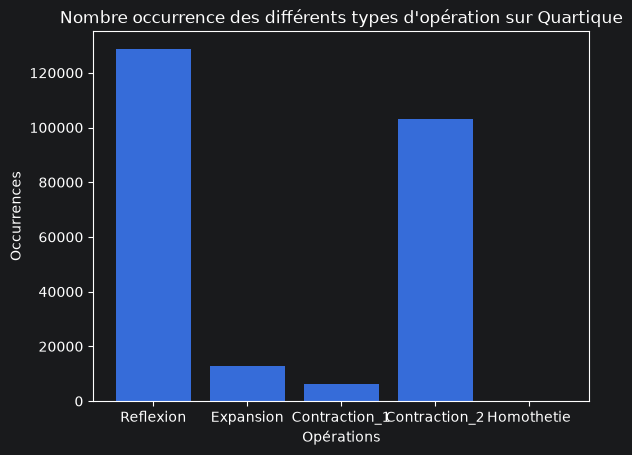

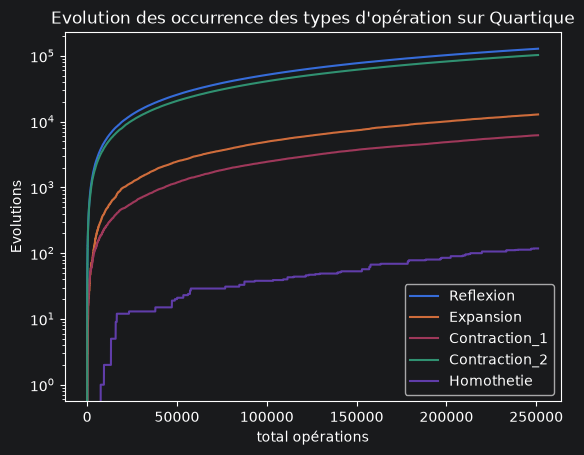

In [3]:
from benchmark.benchmark_utils import *

graph_convergence(best_values, "Quartique")
graph_nelder_mead_type_operation(history_step, "Quartique")
graph_nelder_mead_type_2(history_step, "Quartique")